# 移动 Web 第四天

移动适配—vw（前端第14天）。本课使用视口单位，把设计稿中的尺寸换算为随视口变化的尺寸，再完成酷我音乐页面。配套作业是移动版哔哩哔哩。

资料依据：原课9页PPT、Markdown笔记及11页笔记PDF、XMind、课堂源码、练习素材和作业源码。设计尺寸的说明以375px宽参考视口为准；代码保留原资料的启用与注释状态。


## 1. vw 适配方案

移动端设备的视口宽度不同，同一个固定像素尺寸在不同屏幕上所占的比例会改变。本课目标是：**视口宽度变化时，网页元素的宽高按同一比例缩放**。


### 1.1 vw 和 vh 相对什么计算

视口是浏览器用于布局网页的可见区域。`vw`和`vh`是相对视口的长度单位，写在需要长度的CSS属性中。

| 单位 | 名称 | 1单位对应的长度 | 随什么变化 |
| --- | --- | --- | --- |
| `vw` | viewport width | 视口宽度的1/100 | 视口宽度 |
| `vh` | viewport height | 视口高度的1/100 | 视口高度 |

在375 × 667px视口中，`1vw = 3.75px`，`1vh = 6.67px`；在414 × 736px视口中，`1vw = 4.14px`，`1vh = 7.36px`。宽度属性也可以写`vh`，高度属性也可以写`vw`，属性名不会改变单位的计算基准。

原课用两种设备的页面说明适配目标：375px视口下图标约40px，414px视口下约44.16px，图标随视口一起缩放。

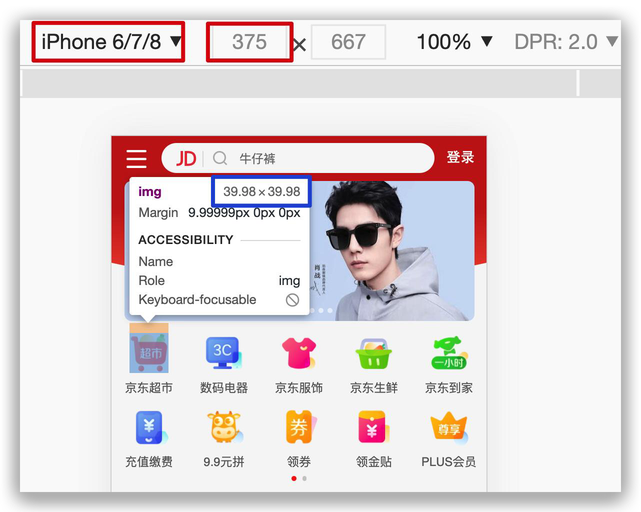

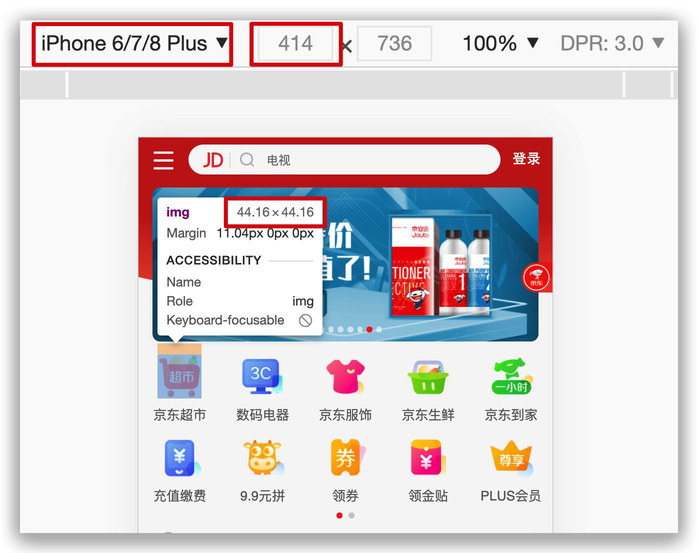

本课HTML均保留移动端视口设置：

```html
<meta name="viewport" content="width=device-width, initial-scale=1.0">
```

`width=device-width`使布局视口采用设备宽度，`initial-scale=1.0`设置初始缩放为1。这里直接使用视口单位，不需要通过JavaScript调整根字号。


### 1.2 直接体验 vw 和 vh

目标文件：`code/01-体验vw和vh.html`。完整源码如下。

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>体验vw和vh</title>
    <style>
      * {
        margin: 0;
        padding: 0;
      }

      /* vw 和 vh 是相对视口宽高计算结果，可以直接实现移动端适配效果 */
      /* .box {
        width: 50vw;
        height: 30vw;
        background-color: pink;
      } */

      .box {
        width: 50vh;
        height: 30vh;
        background-color: green;
      }
    </style>
  </head>
  <body>
    <div class="box"></div>
  </body>
</html>
```

先看注释中的粉色方案：`width: 50vw`、`height: 30vw`都以视口宽度为基准。375px宽时是187.5 × 112.5px；414px宽时是207 × 124.2px，宽高比例保持5:3。

**原文件实际启用的是绿色方案**：宽`50vh`，高`30vh`，两边都以视口高度为基准。667px高时是333.5 × 200.1px，宽高仍为5:3，但只改变视口宽度不会使它缩放。

练习时打开该HTML，用浏览器设备模拟修改视口尺寸。先只改变宽度，再只改变高度；比较启用的绿色盒子和注释中的粉色方案，就能确认两个单位各自依赖什么。切换方案时先注释原方案，避免同一选择器后面的声明覆盖前面。


### 1.3 将设计稿的 px 换算成 vw

换算前先确认设计稿对应的参考视口宽度，不能把当前测试设备宽度反复写进同一份源码。

1. 查看设计稿宽度，确定参考设备的视口宽度。
2. 用参考视口宽度除以100，求出设计基准中的`1vw`。
3. 将设计稿中的px数值除以这个基准，得到应写入CSS的vw数值。

```text
vw数值 = 设计稿中的px数值 ÷ (参考视口宽度 ÷ 100)
实际显示的px长度 = vw数值 × 当前视口宽度 ÷ 100
```

原课框选了一个68 × 29px的盒子：

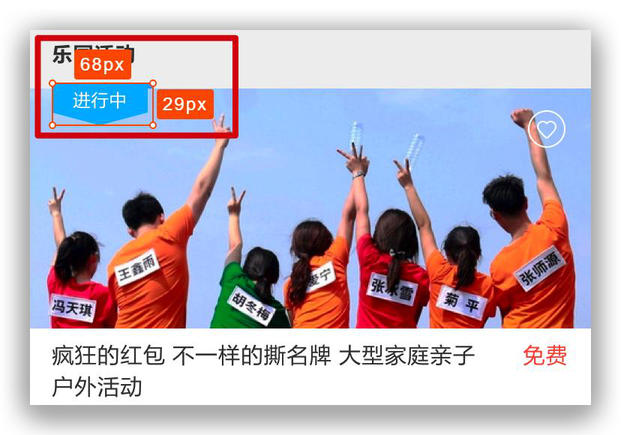

以375px宽为参考，换算基准是3.75：

| 设计尺寸 | 换算 | 写入CSS |
| --- | --- | --- |
| 宽68px | 68 ÷ 3.75 | `18.13333333vw` |
| 高29px | 29 ÷ 3.75 | `7.73333333vw` |

```css
.box {
  width: 18.13333333vw;
  height: 7.73333333vw;
  background-color: pink;
}
```

375px宽时还原为68 × 29px，414px宽时约为75.072 × 32.016px。两边都乘上`414 / 375`，所以比例保持不变。不要因为写的是`height`，就把高度改为`vh`。

原课浏览器样式图显示了`width`、`height`、间距和圆角使用vw的效果：

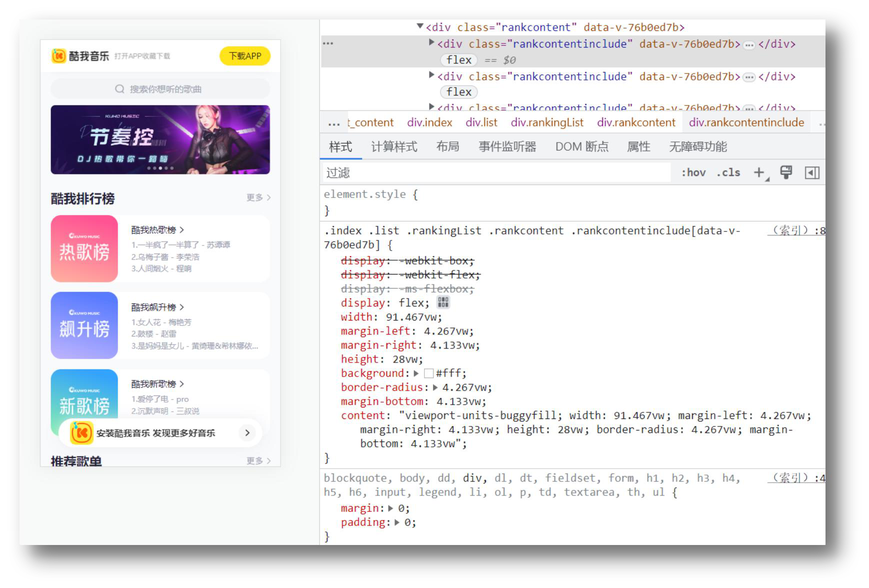


### 1.4 用 Less 完成尺寸换算

目标目录：`code/02-vw适配/`。HTML链接同目录的`demo.css`，浏览器读取编译后的CSS。

`02-vw适配.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>vw适配</title>
    <link rel="stylesheet" href="./demo.css">
</head>
<body>
    <div class="box"></div>
</body>
</html>
```

`demo.less`：

```less
// .box {
//   width: (68 / 3.75vw);
//   height: (29 / 3.75vw);
//   background-color: pink;
// }

.box {
  width: (68 / 6.67vh);
  height: (29 / 6.67vh);
  background-color: green;
}

// px单位尺寸 / 1/100视口的宽度或高度
```

课堂用括号包住除法，例如`(68 / 3.75vw)`，由Less计算出对应的vw值。它是原课的Less写法，不能把这段数学表达式直接当成普通CSS长度填写。

> 补充：目录和HTML标题虽然叫“vw适配”，最终源码中粉色vw方案已经被注释，实际启用的是绿色vh方案。下面的编译结果也对应vh，不能据文件名把它解释成vw效果。

原文件`demo.css`全文：

```css
.box {
  width: 10.19490255vh;
  height: 4.34782609vh;
  background-color: green;
}
```

练习vw方案时，在Less中切换到注释里的两条vw尺寸，保存并使用已有的Less编译方式更新`demo.css`，再刷新HTML。此时应显示粉色盒子，375px宽时约为68 × 29px。若仍是绿色，先检查浏览器链接的CSS是否已更新。


### 1.5 vh 的换算基准是参考视口高度

vh的换算过程与vw相同，但基准改为高度：

```text
vh数值 = 设计稿中的px数值 ÷ (参考视口高度 ÷ 100)
实际显示的px长度 = vh数值 × 当前视口高度 ÷ 100
```

以667px高为参考，`1vh = 6.67px`，因此68px换算为`10.19490255vh`，29px换算为`4.34782609vh`。上一节绿色方案就是这样算出的。

在375 × 667px视口中，绿色盒子约为68 × 29px；视口高度改成812px时，宽高都变为原来的`812 / 667`倍，约82.783 × 35.304px。它保持自身比例，但依赖高度的大小，不是按屏幕宽度适配。

> 补充：PPT的vh步骤沿用了“查看设计稿宽度”的字样。这里计算的是vh，应确认设计稿对应的参考视口高度，不能仍用宽度作为除数。


### 1.6 宽用 vw、高用 vh 为什么可能变形

目标目录：`code/03-vh/`。原课用宽高采用不同基准的盒子说明问题。

`03-vh.html`：

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>vh</title>
    <link rel="stylesheet" href="./demo.css" />
  </head>
  <body>
    <div class="box"></div>
  </body>
</html>
```

`demo.less`：

```less
.box {
  // 68 * 29
  width: (68 / 3.75vw);
  height: (29 / 6.67vh);
  background-color: pink;
}
```

`demo.css`：

```css
.box {
  width: 18.13333333vw;
  height: 4.34782609vh;
  background-color: pink;
}
```

宽度依赖视口宽度，高度依赖视口高度。参考设备上两边分别还原为68px和29px；换到宽度相同、高度更大的视口时，宽不变而高变大。

| 当前视口 | 宽度的计算结果 | 高度的计算结果 | 观察 |
| --- | --- | --- | --- |
| 375 × 667px | 68px | 29px | 还原参考尺寸 |
| 375 × 812px | 68px | 约35.304px | 同宽设备上盒子变高 |
| 414 × 736px | 约75.072px | 32px | 与参考设备宽高比接近，变形不明显 |

> 原课原则：为了按设计稿等比还原，宽高、间距等长度统一使用vw基准。补充：PPT中的“不能混用”针对这个适配目标，CSS语法允许两者并存；问题是不同设备的宽高比变化会让两个缩放倍率不一致。

打开本例，保持375px宽，把高度由667px改为812px。应看到粉色盒子只变高。这与前面的“宽高都用vw”形成对照。


## 2. 综合案例：酷我音乐

沿着原笔记顺序完成准备、头部、搜索、banner、公共标题、排行榜、推荐歌单、下载区域，最后固定头部。

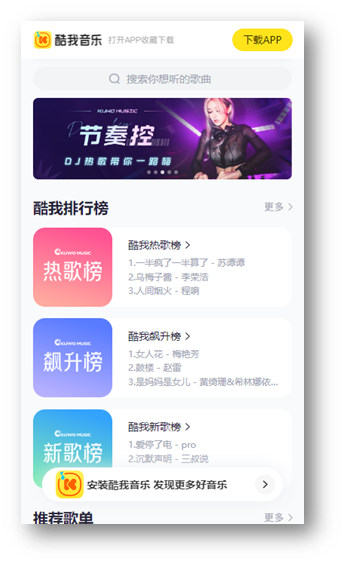

参考图用来观察区域关系。具体文案、榜单顺序和尺寸以配套源码为准：源码依次为热歌榜、新歌榜、飙升榜。


### 2.1 准备目录、基础样式和换算变量

项目在`code/酷我/`。从`素材/酷我/`开始练习时，已有图片、图标字体和`less/base.less`，还需要创建页面及其样式；`code/酷我/`是完成版。

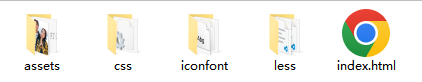

| 路径 | 用途 |
| --- | --- |
| `index.html` | 页面结构，链接图标字体CSS和业务CSS |
| `assets/` | 头部、banner、排行榜、歌单封面及下载logo |
| `iconfont/` | 图标CSS及woff2、woff、ttf字体 |
| `less/base.less` | 初始化样式 |
| `less/index.less` | 引入基础样式，完成页面样式 |
| `css/index.css` | 编译后的CSS，供HTML读取 |

`less/base.less`完整内容：

```less
// out: false
*,
::after,
::before {
  box-sizing: border-box;
}

body,
ul,
p,
h1,
h2,
h3,
h4,
h5,
h6 {
  padding: 0;
  margin: 0;
}

body {
  font-family:
    -apple-system,
    BlinkMacSystemFont,
    PingFangSC-Regular,
    "PingFang SC",
    "Microsoft YaHei",
    "Helvetica Neue",
    Helvetica,
    Arial,
    sans-serif;
  font-size: 14px;
  color: #333;
}

img {
  vertical-align: bottom;
}

ul {
  list-style-type: none;
}

a {
  color: #333;
  text-decoration: none;
  -webkit-tap-highlight-color: rgb(0 0 0 / 0%);
}
```

`box-sizing: border-box`让声明的宽高包含内边距和边框，伪元素也采用这个规则。基础文件还清除标题、段落、列表的默认间距，取消列表标记和链接下划线，并把图片设为底部对齐，避免行内图片基线留下空隙。

`less/index.less`开头：

```less
// out: ../css/

@import "./base";

body {
  background-color: #f9fafb;
}

@vw:3.75vw;
```

`@import "./base"`把基础样式纳入同一份编译结果。`@vw:3.75vw`沿用375px参考宽度：15px写成`(15 / @vw)`，编译后为`4vw`；50px写成`(50 / @vw)`，编译后为`13.33333333vw`。

> 补充：`// out: ../css/`与`// out: false`是原课编辑器编译插件使用的注释约定，不是Less语言自动输出文件的指令。页面只链接CSS；修改Less后要通过已有编译流程更新CSS，单独保存Less不会让浏览器直接读取它。

基础字体仍有`14px`，字体文件默认图标为`16px`，并非每条长度都已换成vw。页面中需要适配的尺寸由业务样式覆盖。


### 2.2 先看完成版 HTML 的区域关系

目标文件：`code/酷我/index.html`。完整结构如下，后面逐区说明样式。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>酷我音乐</title>
  <link rel="stylesheet" href="./iconfont/iconfont.css">
  <link rel="stylesheet" href="./css/index.css">
</head>
<body>
  <!-- 头部 -->
  <header>
    <div class="left"></div>
    <a href="#">下载APP</a>
  </header>

  <!-- 搜索 -->
  <div class="search">
    <div class="txt">
      <span class="iconfont icon-sousuo"></span>
      <span>搜索你想听的歌曲</span>
    </div>
  </div>

  <!-- banner -->
  <div class="banner">
    <ul>
      <li><a href="#"><img src="./assets/banner01.jpeg" alt=""></a></li>
    </ul>
  </div>

  <!-- 排行榜 -->
  <div class="list">
    <!-- 标题 -->
    <div class="title">
      <h4>酷我排行榜</h4>
      <a href="#">更多<span class="iconfont icon-right"></span></a>
    </div>
    <!-- 内容 -->
    <div class="content">
      <ul>
        <li>
          <div class="pic"><img src="./assets/icon_rank_hot.png" alt=""></div>
          <div class="txt">
            <a href="#" class="more">酷我热歌榜<span class="iconfont icon-right"></span></a>
            <a href="#">1.樱花树下的约定（完整版） - 旺仔小乔</a>
            <a href="#">2.就让这大雨全都落下 - 容祖儿</a>
            <a href="#">3.缺氧 - 轩姨（相信光）</a>
          </div>
        </li>
        <li>
          <div class="pic"><img src="./assets/icon_rank_new.png" alt=""></div>
          <div class="txt">
            <a href="#" class="more">酷我新歌榜<span class="iconfont icon-right"></span></a>
            <a href="#">1.樱花树下的约定（完整版） - 旺仔小乔</a>
            <a href="#">2.就让这大雨全都落下 - 容祖儿</a>
            <a href="#">3.缺氧 - 轩姨（相信光）</a>
          </div>
        </li>
        <li>
          <div class="pic"><img src="./assets/icon_rank_rise.png" alt=""></div>
          <div class="txt">
            <a href="#" class="more">酷我飙升榜<span class="iconfont icon-right"></span></a>
            <a href="#">1.樱花树下的约定（完整版） - 旺仔小乔</a>
            <a href="#">2.就让这大雨全都落下 - 容祖儿</a>
            <a href="#">3.缺氧 - 轩姨（相信光）</a>
          </div>
        </li>
      </ul>
    </div>
  </div>

  <!-- 推荐歌单 -->
  <div class="recommend">
    <!-- 标题 -->
    <div class="title">
      <h4>推荐歌单</h4>
      <a href="#">更多<span class="iconfont icon-right"></span></a>
    </div>
    <!-- 内容 -->
    <div class="content">
      <ul>
        <li>
          <div class="pic">
            <img src="./assets/song01.jpeg" alt="">
            <div class="cover">18.2W</div>
          </div>
          <div class="txt">抖音嗨爆DJ！劲爆旋律萦绕双耳</div>
        </li>
        <li>
          <div class="pic">
            <img src="./assets/song02.jpeg" alt="">
            <div class="cover">18.2W</div>
          </div>
          <div class="txt">抖音嗨爆DJ！劲爆旋律萦绕双耳</div>
        </li>
        <li>
          <div class="pic">
            <img src="./assets/song03.jpeg" alt="">
            <div class="cover">18.2W</div>
          </div>
          <div class="txt">抖音嗨爆DJ！劲爆旋律萦绕双耳</div>
        </li>
        <li>
          <div class="pic">
            <img src="./assets/song02.jpeg" alt="">
            <div class="cover">18.2W</div>
          </div>
          <div class="txt">抖音嗨爆DJ！劲爆旋律萦绕双耳</div>
        </li>
        <li>
          <div class="pic">
            <img src="./assets/song03.jpeg" alt="">
            <div class="cover">18.2W</div>
          </div>
          <div class="txt">抖音嗨爆DJ！劲爆旋律萦绕双耳</div>
        </li>
        <li>
          <div class="pic">
            <img src="./assets/song01.jpeg" alt="">
            <div class="cover">18.2W</div>
          </div>
          <div class="txt">抖音嗨爆DJ！劲爆旋律萦绕双耳</div>
        </li>
      </ul>
    </div>
  </div>

  <!-- 安装，下载 -->
  <div class="download">
    <img src="./assets/logo.png" alt="">
    <p>安装酷我音乐 发现更多好音乐</p>
    <span class="iconfont icon-right"></span>
  </div>
</body>
</html>
```

头部、搜索、banner、排行榜、歌单和下载栏按此顺序排列。两处`.title`复用公共标题；三个排行榜条目结构相同，六个歌单条目复用封面、播放量和文字结构。

原HTML只有一张`banner01.jpeg`，没有轮播脚本；`banner02.jpeg`、`banner03.jpeg`虽然在素材中，当前未使用。搜索区域是`div`和`span`，没有输入框。各链接为`href="#"`，底部下载栏是`div`；这是布局练习，源码没有搜索、播放或下载业务。


### 2.3 头部布局

目标文件：`less/index.less`的`header`规则。头部两项分别是`.left`和“下载APP”链接。

使用Flex使它们横向排列，`justify-content: space-between`将两项分布到左右两端，`align-items: center`使下载按钮在50px高的头部内垂直居中。左右15px内边距与后续区域保持统一。

以下保留最终源码的完整头部规则；其中固定定位是原课最后增加的步骤，先理解内部排列，再看2.12节的固定与占位关系。

```less
// 头部
header {
  position: fixed;
  left: 0;
  top: 0;
  display: flex;
  justify-content: space-between;
  align-items: center;
  padding: 0 (15 / @vw);
  // 固定定位的盒子，宽度靠内容撑开，希望宽度100%
  width: 100%;
  height: (50 / @vw);
  background-color: #fff;
  // 左边
  .left {
    width: (235 / @vw);
    height: (50 / @vw);
    background-image: url(../assets/head.png);
    background-size: contain;
    background-repeat: no-repeat;
  }
  a {
    width: (80 / @vw);
    height: (30 / @vw);
    background-color: #ffe31b;
    border-radius: (15 / @vw);
    text-align: center;
    line-height: (30 / @vw);
    font-size: (14 / @vw);
  }
}
```

375px宽时，头部可用内容宽度是`375 - 15 × 2 = 345px`。左侧235px、按钮80px，共315px，Flex在两项之间分配剩余30px。


### 2.4 头部内容：背景标识与圆角按钮

继续看上一节的`.left`与`a`：

- `.left`宽235px、高50px，使用`head.png`作为背景。`background-size: contain`在盒子内完整显示背景图，`no-repeat`避免平铺。
- 下载按钮宽80px、高30px，背景`#ffe31b`，圆角15px。圆角等于高度的一半，形成胶囊形。
- `text-align: center`使文字水平居中；`line-height`与30px高度相同，使单行文字垂直居中；字体14px。

这些尺寸都通过`@vw`换算。改变视口宽度后，头部高度、左侧图形、按钮和间距应按相同倍率变化。原HTML的`.left`没有“left”占位文字，实际内容由背景图呈现。


### 2.5 搜索区域

目标规则：`.search`。外层负责留白，内层`.txt`形成灰色圆角条；搜索图标和提示文字都在内层中。

```less
// 搜索
.search {
  // 头部固定定位，脱标不占位，搜索去最顶了，加上外边距挤下来即可
  margin-top: (50 / @vw);
  padding: (10 / @vw) (15 / @vw);
  height: (52 / @vw);
  // background-color: pink;
  .txt {
    height: (32 / @vw);
    background-color: #f2f4f5;
    border-radius: (16 / @vw);
    text-align: center;
    line-height: (32 / @vw);
    color: #a1a4b3;
    font-size: (14 / @vw);
    .iconfont {
      font-size: (16 / @vw);
    }
  }
}
```

375px宽时外层高52px，上下各10px内边距，留给内层`52 - 20 = 32px`，与`.txt`高度吻合。基础样式启用了`border-box`，因此外层不是52px再加20px。

内层圆角16px是32px高度的一半；文字和图标分别按14px、16px换算。`text-align`与等高行高把单行内容居中。粉色背景仍处于注释状态。

最终代码的`margin-top: (50 / @vw)`用于给固定头部让位，在2.12节解释。这里的52px是设计值，实际CSS为`13.86666667vw`，不能直接写成`52vw`。


### 2.6 banner 区域与图片裁切

目标规则：`.banner`。页面左右各留15px，375px宽时内容宽345px，banner高108px。

```less
// banner
.banner {
  padding: 0 (15 / @vw);
  height: (108 / @vw);
  // background-color: pink;
  ul {
    li {
      width: (345 / @vw);
      height: (108 / @vw);
      img {
        width: 100%;
        height: 100%;
        // cover完全覆盖
        // 缩放img，图片比例跟父级盒子比例不同，避免图片挤压变形
        object-fit: cover;
        border-radius: (5 / @vw);
      }
    }
  }
}
```

HTML用`ul > li > a > img`包裹一张banner。图片的宽高都填满345 × 108px的盒子；`object-fit: cover`按图片自身比例缩放，使盒子被覆盖，比例不同的部分会被裁切。它避免把图片直接挤压成盒子的比例。

`border-radius`按5px换算；调试时的粉色背景被注释。完成后应看到与搜索条左右对齐的圆角banner，切换视口宽度时图片盒子等比缩放。


### 2.7 抽取公共标题

排行榜和推荐歌单都有“左边标题、右边更多”的结构，两处共用`.title`，不用各写一套。

目标规则：`less/index.less`中的公共`.title`：

```less
// 标题 → 公共样式
.title {
  display: flex;
  justify-content: space-between;
  margin-bottom: (16 / @vw);
  line-height: (25 / @vw);
  h4 {
    font-size: (20 / @vw);
  }
  a {
    font-size: (12 / @vw);
    color: #a1a4b3;
  }
}
```

Flex把标题和“更多”分到两端。标题下方留16px，行高25px；`h4`为20px，右侧链接为12px、灰色`#a1a4b3`。

排行榜外层还需20px上间距、15px左右内边距，完整`.list`规则在下一节。原笔记先讲标题，最终Less把`.title`写在`.list`之后，两者选择不同的区域，不影响这一步的学习顺序。

> 补充：公共标题里的右箭头没有单独覆盖字体大小，沿用`iconfont.css`中的16px。不要把它误记成已经随vw变化的图标。


### 2.8 排行榜内容

目标规则：`.list`。每个`li`用Flex把榜单图片与右侧文字放在同一行。

```less
// 排行榜
.list {
  margin-top: (20 / @vw);
  padding: 0 (15 / @vw);
  li {
    display: flex;
    margin-bottom: (16 / @vw);
    height: (105 / @vw);
    background-color: #fff;
    border-radius: (10 / @vw);
    .pic {
      margin-right: (20 / @vw);
      img {
        width: (105 / @vw);
        height: (105 / @vw);
        border-radius: (10 / @vw);
      }
    }
    .txt {
      a {
        display: block;
        font-size: (12 / @vw);
        color: #a1a4b3;
        line-height: 1.8;
      }

      .more {
        font-size: (14 / @vw);
        color: #333;
        .iconfont {
          font-size: (16 / @vw);
        }
      }
    }
  }
}
```

375px宽时，每个白色条目高105px，下间距16px，圆角10px。榜单图片是105 × 105px，右边留20px，与文字隔开；图片本身也设10px圆角。

右侧链接设为块级，每条占一行。歌曲链接按12px、灰色显示，`line-height: 1.8`表示行高是字号的1.8倍；榜名`.more`覆盖成14px、深色，内部箭头按16px换算。

源码三个条目依次使用`icon_rank_hot.png`、`icon_rank_new.png`、`icon_rank_rise.png`，歌曲文本重复。完成后检查三张图与各榜名相匹配，条目之间的留白一致。

> 补充：这一版没有给长歌名设置省略号或专门的最小宽度控制。更长的文字可能换行或挤占空间，不能把示例效果解释为已实现文字截断。


### 2.9 推荐歌单布局

目标规则：`.recommend`。仍然左右留15px，标题复用`.title`。内容`ul`使用Flex、允许换行，并用`space-between`分配每行的空余空间。

以下是原文件的完整推荐区域规则，包含下一节要讲的图片与文字；保留原缩进及注释状态。

```less
// 推荐歌单
.recommend {
  padding: 0 (15 / @vw);
  ul {
    display: flex;
    flex-wrap: wrap;
    justify-content: space-between;
    li {
      margin-bottom: (16 / @vw);
      width: (105 / @vw);
      height: (143 / @vw);
      // background-color: pink;
  // 图片
  .pic {
    position: relative;
    width: (105 / @vw);
    height: (105 / @vw);
    img {
      width: 100%;
      height: 100%;
      object-fit: cover;
      border-radius: (10 / @vw);
    }
    .cover {
      position: absolute;
      left: 0;
      bottom: 0;
      width: (70 / @vw);
      height: (28 / @vw);
      background-color: rgba(0,0,0,0.8);
      border-radius: 0 (10 / @vw) 0 (10 / @vw);
      text-align: center;
      line-height: (28 / @vw);
      color: #fff;
      font-size: (14 / @vw);
    }
      }
      // 文字
      .txt {
        font-size: (14 / @vw);
      }
    }
  }
}
```

每个`li`设计宽105px、高143px，下间距16px。375px宽时可用345px，一行放三个105px条目：`345 - 105 × 3 = 30px`，分到两个间隙后各15px。六个条目排成两行。

原笔记搭建布局阶段用粉色背景帮助观察；最终源码已经注释这条背景。用完成版验证时应看到歌单图片和文字，不应把整张卡片描述成粉色。


### 2.10 推荐歌单内容与封面上的播放量

继续看上一节内部的`.pic`、`.cover`和`.txt`。

`.pic`设为105 × 105px并采用相对定位，作为播放量的定位参考。图片宽高100%，用`object-fit: cover`填满正方形，圆角10px。

`.cover`绝对定位在图片左下角：宽70px、高28px，黑色背景透明度为0.8，白色14px文字居中。`border-radius: 0 (10 / @vw) 0 (10 / @vw)`的顺序是左上、右上、右下、左下，因此右上和左下有圆角。

下方`.txt`字号14px。HTML六张封面顺序是`song01`、`song02`、`song03`、`song02`、`song03`、`song01`，播放量均为`18.2W`，文案相同。

检查播放量是否贴在各自图片左下角，滚动时是否随该图片一起移动。这里的绝对定位元素不占图片后的正常文档位置。

> 补充：143px是原卡片高度，源码没有单独限制文字高度，也没有设置多行省略。示例文字的换行效果不能直接推广为任意文案都不溢出。


### 2.11 固定下载区域

目标规则：`.download`。用`position: fixed`使下载栏固定在视口下方，左右区域与页面内容对齐。

```less
// 下载
.download {
  position: fixed;
  left: (15 / @vw);
  bottom: (30 / @vw);

  display: flex;
  align-items: center;
  padding: 0 (10 / @vw) 0 (15 / @vw);
  width: (345 / @vw);
  height: (45 / @vw);
  background-color: #fff;
  border-radius: (22 / @vw);
  img {
    margin-right: (10 / @vw);
    width: (36 / @vw);
    height: (36 / @vw);
  }
  p {
    flex: 1;
    font-size: (14 / @vw);
  }
  span {
    width: (32 / @vw);
    height: (32 / @vw);
    background-color: #f2f3f5;
    border-radius: 50%;
    text-align: center;
    line-height: (32 / @vw);
    font-size: (16 / @vw);
  }
}
```

以375px宽为参考，左侧15px、宽345px，所以右侧也余15px；距离底部30px，栏高45px，圆角按原值22px换算。固定定位的`bottom`这里最终为`8vw`，仍然按视口宽度缩放。

下载栏用Flex垂直居中：logo36 × 36px，右间距10px；段落`flex: 1`占据剩余空间；右边箭头放在32 × 32px的浅灰圆形内。整体内边距为左15px、右10px。

上下滚动时，这条下载栏应停留在视口下方，普通内容从其后方经过。

> 补充：固定定位脱离文档流，原源码没有为这个底栏增加页面底部占位，可能遮挡末尾歌单。下载提示的HTML也没有下载地址或点击逻辑，当前验证的是位置和样式。


### 2.12 最后固定头部，并为搜索区域让位

原课在内部布局完成后，为`header`增加`position: fixed`、`left: 0`、`top: 0`和`width: 100%`。这几条已经保留在2.3节的最终规则中。

固定定位让头部脱离文档流，原来占用的50px空间消失，搜索区域会向上移动。原课在`.search`上增加`margin-top: (50 / @vw)`，给它让出与头部等高的距离；这条也已经保留在2.5节的最终规则中。

```text
header高度：50 ÷ 3.75 = 13.33333333vw
search上外边距：50 ÷ 3.75 = 13.33333333vw
```

固定头部仍需显式100%宽度，才能铺满视口。这里的15px左右内边距包含在宽度内，因为基础样式用了`border-box`。

验证时先看页面顶部：搜索内容应位于头部下方；再向下滚动：头部位置固定，正文滚动。改变宽度后，头部高度与让位的外边距应同步缩放。

> 补充：这份酷我源码没有设置头部的`z-index`，后面的相对定位图片等元素可能在滚动时覆盖头部。源码可说明固定位置，但不能据此断言头部始终盖住所有内容。


### 2.13 图标字体如何接入

`index.html`先链接`iconfont/iconfont.css`，再链接`css/index.css`。前者提供字体和图标类，后者覆盖搜索、榜名、下载栏中需要适配的图标字号。

`iconfont/iconfont.css`完整内容：

```css
@font-face {
  font-family: "iconfont"; /* Project id 3868932 */
  src: url('./font_3868932_u1v3wepyjq.woff2') format('woff2'),
       url('./font_3868932_u1v3wepyjq.woff') format('woff'),
       url('./font_3868932_u1v3wepyjq.ttf') format('truetype');
}

.iconfont {
  font-family: "iconfont" !important;
  font-size: 16px;
  font-style: normal;
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

.icon-sousuo:before {
  content: "\e8b9";
}

.icon-up:before {
  content: "\e658";
}

.icon-left:before {
  content: "\e659";
}

.icon-down:before {
  content: "\e65a";
}

.icon-right:before {
  content: "\e65b";
}

.icon-search:before {
  content: "\e8ef";
}

.icon-sync:before {
  content: "\e786";
}

.icon-edit-square:before {
  content: "\e791";
}

.icon-appstore:before {
  content: "\e792";
}

.icon-cloud-upload:before {
  content: "\e7d9";
}

.icon-sound:before {
  content: "\e7da";
}

.icon-block:before {
  content: "\e7df";
}

.icon-pic-left:before {
  content: "\e7f6";
}

.icon-crown:before {
  content: "\e842";
}

.icon-desktop:before {
  content: "\e843";
}
```

`@font-face`中的地址相对这份CSS所在的`iconfont/`目录。HTML把基础类`iconfont`与具体类一起写，例如`icon-sousuo`显示搜索图标，`icon-right`显示右箭头；具体字符由伪元素的`content`提供。

若图标变成方块或没有出现，检查CSS链接、类名和字体文件路径。复制项目练习时应一起保留字体文件，不能只复制CSS。


### 2.14 编译结果与整页核对

`code/酷我/css/index.css`是原资料自带的完整编译结果，包含`base.less`的初始化样式以及展开后的嵌套选择器。

```css
*,
::after,
::before {
  box-sizing: border-box;
}
body,
ul,
p,
h1,
h2,
h3,
h4,
h5,
h6 {
  padding: 0;
  margin: 0;
}
body {
  font-family: -apple-system, BlinkMacSystemFont, PingFangSC-Regular, "PingFang SC", "Microsoft YaHei", "Helvetica Neue", Helvetica, Arial, sans-serif;
  font-size: 14px;
  color: #333;
}
img {
  vertical-align: bottom;
}
ul {
  list-style-type: none;
}
a {
  color: #333;
  text-decoration: none;
  -webkit-tap-highlight-color: rgba(0, 0, 0, 0);
}
body {
  background-color: #f9fafb;
}
header {
  position: fixed;
  left: 0;
  top: 0;
  display: flex;
  justify-content: space-between;
  align-items: center;
  padding: 0 4vw;
  width: 100%;
  height: 13.33333333vw;
  background-color: #fff;
}
header .left {
  width: 62.66666667vw;
  height: 13.33333333vw;
  background-image: url(../assets/head.png);
  background-size: contain;
  background-repeat: no-repeat;
}
header a {
  width: 21.33333333vw;
  height: 8vw;
  background-color: #ffe31b;
  border-radius: 4vw;
  text-align: center;
  line-height: 8vw;
  font-size: 3.73333333vw;
}
.search {
  margin-top: 13.33333333vw;
  padding: 2.66666667vw 4vw;
  height: 13.86666667vw;
}
.search .txt {
  height: 8.53333333vw;
  background-color: #f2f4f5;
  border-radius: 4.26666667vw;
  text-align: center;
  line-height: 8.53333333vw;
  color: #a1a4b3;
  font-size: 3.73333333vw;
}
.search .txt .iconfont {
  font-size: 4.26666667vw;
}
.banner {
  padding: 0 4vw;
  height: 28.8vw;
}
.banner ul li {
  width: 92vw;
  height: 28.8vw;
}
.banner ul li img {
  width: 100%;
  height: 100%;
  object-fit: cover;
  border-radius: 1.33333333vw;
}
.list {
  margin-top: 5.33333333vw;
  padding: 0 4vw;
}
.list li {
  display: flex;
  margin-bottom: 4.26666667vw;
  height: 28vw;
  background-color: #fff;
  border-radius: 2.66666667vw;
}
.list li .pic {
  margin-right: 5.33333333vw;
}
.list li .pic img {
  width: 28vw;
  height: 28vw;
  border-radius: 2.66666667vw;
}
.list li .txt a {
  display: block;
  font-size: 3.2vw;
  color: #a1a4b3;
  line-height: 1.8;
}
.list li .txt .more {
  font-size: 3.73333333vw;
  color: #333;
}
.list li .txt .more .iconfont {
  font-size: 4.26666667vw;
}
.title {
  display: flex;
  justify-content: space-between;
  margin-bottom: 4.26666667vw;
  line-height: 6.66666667vw;
}
.title h4 {
  font-size: 5.33333333vw;
}
.title a {
  font-size: 3.2vw;
  color: #a1a4b3;
}
.recommend {
  padding: 0 4vw;
}
.recommend ul {
  display: flex;
  flex-wrap: wrap;
  justify-content: space-between;
}
.recommend ul li {
  margin-bottom: 4.26666667vw;
  width: 28vw;
  height: 38.13333333vw;
}
.recommend ul li .pic {
  position: relative;
  width: 28vw;
  height: 28vw;
}
.recommend ul li .pic img {
  width: 100%;
  height: 100%;
  object-fit: cover;
  border-radius: 2.66666667vw;
}
.recommend ul li .pic .cover {
  position: absolute;
  left: 0;
  bottom: 0;
  width: 18.66666667vw;
  height: 7.46666667vw;
  background-color: rgba(0, 0, 0, 0.8);
  border-radius: 0 2.66666667vw 0 2.66666667vw;
  text-align: center;
  line-height: 7.46666667vw;
  color: #fff;
  font-size: 3.73333333vw;
}
.recommend ul li .txt {
  font-size: 3.73333333vw;
}
.download {
  position: fixed;
  left: 4vw;
  bottom: 8vw;
  display: flex;
  align-items: center;
  padding: 0 2.66666667vw 0 4vw;
  width: 92vw;
  height: 12vw;
  background-color: #fff;
  border-radius: 5.86666667vw;
}
.download img {
  margin-right: 2.66666667vw;
  width: 9.6vw;
  height: 9.6vw;
}
.download p {
  flex: 1;
  font-size: 3.73333333vw;
}
.download span {
  width: 8.53333333vw;
  height: 8.53333333vw;
  background-color: #f2f3f5;
  border-radius: 50%;
  text-align: center;
  line-height: 8.53333333vw;
  font-size: 4.26666667vw;
}
```

修改Less后，用已有编译方式生成这份CSS，再打开`index.html`。重点核对下面几组尺寸：

| 项目 | 375px宽下的设计值 | 编译后的值 |
| --- | --- | --- |
| 页面左右留白 | 15px | `4vw` |
| 头部高度与搜索让位 | 50px | `13.33333333vw` |
| banner内容宽 | 345px | `92vw` |
| 排行榜图、歌单封面宽 | 105px | `28vw` |
| 下载栏底部距离 | 30px | `8vw` |

用375px、414px两种视口检查左右对齐、歌单三列、封面裁切和固定栏位置。再保持宽度、只改变高度：普通内容的vw尺寸应不变，底部固定栏随视口底边移动。所有链接仍是原源码的占位链接。


## 3. 配套作业：移动版哔哩哔哩

资料在`作业/m-bilibili/`。这部分来自同一天配套作业，继续练习vw、Flex、定位、渐变与文字省略；不属于PPT额外增加的新章节。


### 3.1 项目准备和换算写法

目录包含`index.html`、`less/base.less`、`less/index.less`、`css/index.css`，以及`font/`和`images/`。页面同样链接字体CSS与编译后的业务CSS。

作业的`less/base.less`完整内容：

```less
// out:false

* {
    margin: 0;
    padding: 0;
    box-sizing: border-box;
    -webkit-font-smoothing: antialiased;
    -webkit-tap-highlight-color: rgba(0,0,0,0);
  }
  
  body {
    font-family: Helvetica Neue,Tahoma,Arial,PingFangSC-Regular,Hiragino Sans GB,Microsoft Yahei,sans-serif;
  }
  
  a {
    color: #333;
    text-decoration: none;
  }
  
  img {
    vertical-align: middle;
    width: 100%;
    height: 100%;
  }
  ul {
    list-style: none;
  }
  
  .ellipsis-2 {
    overflow: hidden;
    text-overflow: ellipsis;
    display: -webkit-box;
    -webkit-line-clamp: 2;
    -webkit-box-orient: vertical;
  }
```

本例初始化了全部元素的间距和盒模型，并提供`.ellipsis-2`两行省略样式。图片默认宽高100%、垂直居中，因此具体图片尺寸由所在的页面结构控制。

`less/index.less`开头：

```less
// out: ../css/

// 导入初始化样式
@import 'base.less';

@mainColor: #fb7299;
@ratio: 3.75;
```

`@mainColor`统一粉色`#fb7299`。这里`@ratio: 3.75`是无单位数字，长度写成`(84vw / @ratio)`，即`84vw ÷ 3.75 = 22.4vw`。

它与酷我的写法形式不同：酷我变量带单位`@vw: 3.75vw`，使用`(84 / @vw)`；作业把单位放在分子。两套课堂写法都通过Less产生vw结果，摘录时保留各自形式，不混着替换变量。


### 3.2 完成版 HTML

目标文件：`作业/m-bilibili/index.html`。完整结构如下。

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>bilibili</title>
    <link rel="stylesheet" href="./font/iconfont.css">
    <link rel="stylesheet" href="./css/index.css">
</head>

<body>
    <!-- 头部 -->
    <header class="header">
        <!-- navbar -->
        <nav class="navbar">
            <div class="left">
                <a href="#">
                    <i class="iconfont Navbar_logo"></i>
                </a>
            </div>
            <div class="right">
                <a href="#" class="iconfont ic_search_tab"></a>
                <a href="#" class="login">
                    <img src="./images/login.png" alt="">
                </a>
                <a href="#" class="download">
                    <img src="./images/download.png" alt="">
                </a>
            </div>
        </nav>

        <!-- 菜单 menu -->
        <div class="menu">
            <div class="tab">
                <ul>
                    <li class="active"><a href="#" >首页</a></li>
                    <li><a href="#">动画</a></li>
                    <li><a href="#">番剧</a></li>
                    <li><a href="#">国创</a></li>
                    <li><a href="#">音乐</a></li>
                </ul>
            </div>
            <a href="#" class="more">
                <i class="iconfont general_pulldown_s"></i>
            </a>
        </div>
    </header>
    <!-- 头部 -->

    <!-- 内容 -->
    <section class="main">
        <div class="video-list">
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
            <a href="#" class="video-item">
                <div class="card">
                    <img src="./images/1.jpg" alt="">
                    <div class="count">
                        <p>
                            <i class="iconfont icon_shipin_bofangshu"></i>
                            <span>132</span>万
                        </p>
                        <p>
                            <i class="iconfont icon_shipin_danmushu"></i>
                            <span>2.4</span>万
                        </p>
                    </div>
                </div>
                <p class="title ellipsis-2">你活着补刀就是对我最大的侮辱，韩服最强王者组单杀集锦#19</p>
            </a>
        </div>
    </section>
    <!-- 内容 -->

    <div class="btn">
        <a href="#">
            <i class="iconfont Navbar_logo"></i>
            <span>打开App，看你感兴趣的视频</span>
        </a>
    </div>
</body>

</html>
```

头部包含上方导航和下方菜单，主体是两列视频卡片，底部是打开App按钮。`首页`的`li`预先带有`active`类；视频标题同时带`title`和`ellipsis-2`。

源码共12张卡片，均使用`images/1.jpg`和同一标题，播放量132万、弹幕2.4万；`images/2.jpg`未被当前HTML使用。链接均为`href="#"`，没有菜单切换、播放、登录或打开App的JavaScript逻辑。


### 3.3 固定头部与导航栏

目标规则：`.header`。完整头部样式如下，菜单部分在下一节继续说明。

```less
// 头部
.header {
    position: fixed;
    left: 0;
    top: 0;
    width: 100%;
    height: (84vw / @ratio);
    background-color: #fff;

    // 默认值0，后来者居上，取值是整数， 取值越大，显示顺序越靠上
    z-index: 1;


    // navbar
    .navbar {
        display: flex;
        justify-content: space-between;
        align-items: center;
        height: (44vw / @ratio);
        padding: 0 (12vw / @ratio) 0 (18vw / @ratio);
        // background-color: #ccc;

        // left
        .left {
            .Navbar_logo {
                font-size: (28vw / @ratio);
                color: @mainColor;
            }
        }

        // right
        .right {
            display: flex;
            align-items: center;
            .ic_search_tab {
                font-size: (22vw / @ratio);
                color: #ccc;
            }

            // 登录
            .login {
                width: (24vw / @ratio);
                height: (24vw / @ratio);
                margin-left: (24vw / @ratio);
            }

            // 下载
            .download {
                width: (72vw / @ratio);
                height: (24vw / @ratio);
                margin-left: (24vw/ @ratio);
            }
        }
    }

    // 菜单 menu
    .menu {
        position: relative;
        height: (39vw / @ratio);
        padding-right: (40vw / @ratio);
        border-bottom: 1px solid #eee;
        overflow: hidden;

        .tab {
            ul {
                display: flex;
                li {
                    padding: 0 (16vw / @ratio);

                    a {
                        display: block;
                        height: (38vw / @ratio);
                        line-height: (38vw / @ratio);
                        font-size: (14vw / @ratio);
                        border-bottom: 2px solid transparent;
                        
                    }
                    &.active {
                        a {
                            color: @mainColor;
                            border-bottom-color: @mainColor;
                        }
                    }
                }
            }
        }

        .more {
            position: absolute;
            right: 0;
            top: 0;
            width: (40vw / @ratio);
            height: (40vw / @ratio);
            // background-color: pink;
            text-align: center;
            line-height: (40vw / @ratio);
            color: #ccc;
            i {
                font-size: (20vw / @ratio);
            }
        }
    }


}
```

头部固定在左上角，宽100%，设计高84px。`z-index: 1`将头部放在当前作业普通内容及默认定位内容之上，便于滚动时保持可见。

> 补充：原注释写“默认值0”，CSS的`z-index`初始值实际为`auto`。本例显式写1；不能把同一层叠上下文内的大小比较，推广成任意元素之间都只比较数字。

`.navbar`高44px，用Flex让标识和右侧区域分居两端、垂直居中，左内边距18px、右12px。标识图标字号28px、主色粉色；右侧也用Flex排列：搜索图标22px，登录图24 × 24px，下载图72 × 24px，后两项左间距均24px。

在375px宽下核对这些设计尺寸，在414px宽下应共同乘上`414 / 375`。图片的默认100%宽高来自`base.less`，填入登录和下载链接各自的盒子。


### 3.4 菜单、选中状态和更多按钮

继续看上一节`.menu`的嵌套规则。

菜单设计高39px，底部1px浅灰边框。`ul`用Flex排成一行，`li`左右各留16px；内部链接显示为块，设计高度和行高38px，字号14px。

所有链接先设2px透明底边框，避免选中时临时增加边框改变布局。Less的`&.active`把当前`li`与`.active`拼在一起，编译为`.header .menu .tab ul li.active a`，将当前链接文字和底边框改为主色。

右侧“更多”以`.menu`为定位参考，绝对定位在右上角，40 × 40px，箭头字号20px。菜单右侧40px内边距为它预留区域；`overflow: hidden`裁掉溢出菜单范围的内容。

> 补充：源码导航44px与菜单39px合计83px，外层头部高度仍为原值84px。本笔记保留这组尺寸。选中状态是HTML预设，点击其他菜单不会自动切换`active`。


### 3.5 视频双列布局、统计遮罩与标题省略

目标规则：`.main`。

```less
// 内容
.main {
    padding: (84vw / @ratio) (5vw/@ratio) 0;

    .video-list {
        display: flex;
        flex-wrap: wrap;
        font-size: (12vw / @ratio);

        .video-item {
            width: 50%;
            padding: (8vw / @ratio) (5vw / @ratio);

            .card {
                position: relative;

                .count {
                    position: absolute;
                    left: 0;
                    bottom: 0;
                    display: flex;
                    justify-content: space-between;
                    width: 100%;
                    padding: (8vw / @ratio);
                    background-image: linear-gradient(to top, rgba(0, 0, 0, 0.6), rgba(0, 0, 0, 0));
                    color: #fff;

                    i {
                        vertical-align: middle;
                    }
                }
            }
            .title {
                margin-top: (6vw / @ratio);
            }
        }
    }
}
```

主体上内边距84px给固定头部让位，左右各5px。`.video-list`允许Flex换行，卡片宽50%，每项上下8px、左右5px内边距；配合`border-box`，两项能放在同一行。列表字号按12px换算。

`.card`相对定位；播放量和弹幕量所在的`.count`绝对定位到封面底部，宽100%，Flex把两组统计分到两端，内边距8px。由下向上的渐变从黑色0.6透明度过渡到全透明，增强底部白字的可读性；统计图标用`vertical-align: middle`与文字对齐。

标题上间距6px，并通过基础文件的`.ellipsis-2`实现两行省略：`overflow: hidden`隐藏溢出，`display: -webkit-box`配合`-webkit-line-clamp: 2`与纵向排列限制两行。

完成后检查两列卡片、图片底部左右统计和标题行数。作业没有给封面显式指定16:9尺寸，也没有使用`object-fit`；不要把素材本身的形状解释成源码设置了固定宽高比。


### 3.6 底部打开 App 按钮

目标规则：`.btn`。

```less
// 打开按钮
.btn {
    position: fixed;
    left: 0;
    bottom: (30vw / @ratio);
    width: 100%;
    height: (36vw / @ratio);
    padding: (12vw / @ratio);

    a {
        display: block;
        height: (36vw / @ratio);
        background-color: @mainColor;
        border-radius: (18vw / @ratio);
        text-align: center;
        line-height: (36vw / @ratio);
        color: #fff;
        box-shadow: 0 0 (12vw / @ratio) rgba(0,0,0,0.2);

        span {
            font-size: (14vw / @ratio);
        }
    }
}
```

外层固定在视口底部附近，宽100%，设计底部距离30px、高36px、内边距12px。内层链接显示为块，高36px、圆角18px，背景主色，文字白色，行高等于高度；阴影模糊半径12px、黑色透明度0.2。提示文字字号14px。

> 补充：外层用了`border-box`，36px总高减去上下24px内边距后只剩12px内容高，但内层链接仍高36px，会溢出外层内容区。按原尺寸，375px宽时可见按钮下边缘约距视口底部18px，不能直接把外层的30px当成按钮下边缘距离。这里保留原代码与实际盒模型关系。

滚动页面时按钮位置固定。源码没有为底部按钮增加主体底部占位，末尾内容可能被遮挡；`href="#"`也没有连接实际App。


### 3.7 作业图标字体

字体路径相对`font/iconfont.css`，目录内保留eot、woff、ttf和svg文件。以下是配套完整CSS；正文使用标识、搜索、下拉、播放量和弹幕量几类，其余类随原字体资料保留。

```css
@font-face {
    font-family: iconfont;
    src: url(./iconfont.eot);
    src: url(./iconfont.eot#iefix) format("embedded-opentype"), url(./iconfont.woff) format("woff"), url(./iconfont.ttf) format("truetype"), url(./iconfont.svg#iconfont) format("svg")
}

.iconfont {
    font-family: iconfont!important;
    font-size: 4.26667vw;
    font-style: normal;
    -webkit-font-smoothing: antialiased;
    -moz-osx-font-smoothing: grayscale
}

.like2:before {
    content: "\e636"
}

.Blocked:before {
    content: "\e635"
}

.dianying:before {
    content: "\e634"
}

.huancun:before {
    content: "\e631"
}

.qingxidu:before {
    content: "\e632"
}

.dianzan:before {
    content: "\e633"
}

.Like:before {
    content: "\e630"
}

.History:before {
    content: "\e68d"
}

.fanju:before {
    content: "\e62f"
}

.ic_up:before {
    content: "\e741"
}

.notice:before {
    content: "\e62e"
}

.loading:before {
    content: "\eee3"
}

.guanbi:before {
    content: "\e62d"
}

.icon_fenqudaohang_paihangbang:before {
    content: "\e737"
}

.gengduo1:before {
    content: "\e602"
}

.live:before {
    content: "\e62c"
}

.ic_vip_badge:before {
    content: "\e62b"
}

.ic_popular:before {
    content: "\e62a"
}

.general_pulldown_s:before {
    content: "\e6eb"
}

.general_pullup_s:before {
    content: "\e6ec"
}

.icon_comment:before {
    content: "\e629"
}

.icon_download:before {
    content: "\e626"
}

.icon_share:before {
    content: "\e627"
}

.icon_fav:before {
    content: "\e628"
}

.general_complete:before {
    content: "\e625"
}

.ic_add1:before {
    content: "\e624"
}

.ic_female:before {
    content: "\e623"
}

.ic_male:before {
    content: "\e622"
}

.info_warning:before {
    content: "\e621"
}

.ic_userlevel_3:before {
    content: "\e61a"
}

.ic_userlevel_2:before {
    content: "\e61b"
}

.ic_userlevel_5:before {
    content: "\e61c"
}

.ic_userlevel_4:before {
    content: "\e61d"
}

.ic_userlevel_1:before {
    content: "\e61e"
}

.ic_userlevel_6:before {
    content: "\e61f"
}

.error:before {
    content: "\e620"
}

.icon_xinxi_pinglunshu:before {
    content: "\e618"
}

.icon_xinxi_yuedushu:before {
    content: "\e619"
}

.icon_shipin_danmushu:before {
    content: "\e616"
}

.icon_shipin_bofangshu:before {
    content: "\e617"
}

.ic_search_tab:before {
    content: "\e615"
}

.Navbar_logo:before {
    content: "\e614"
}
```

基础图标字号为`4.26667vw`，375px宽时约16px。头部标识、搜索和更多按钮的图标被业务样式覆盖；卡片统计和底部按钮标识沿用基础字号。


### 3.8 编译结果与作业检查

原`作业/m-bilibili/css/index.css`完整内容：

```css
* {
  margin: 0;
  padding: 0;
  box-sizing: border-box;
  -webkit-font-smoothing: antialiased;
  -webkit-tap-highlight-color: rgba(0, 0, 0, 0);
}
body {
  font-family: Helvetica Neue, Tahoma, Arial, PingFangSC-Regular, Hiragino Sans GB, Microsoft Yahei, sans-serif;
}
a {
  color: #333;
  text-decoration: none;
}
img {
  vertical-align: middle;
  width: 100%;
  height: 100%;
}
ul {
  list-style: none;
}
.ellipsis-2 {
  overflow: hidden;
  text-overflow: ellipsis;
  display: -webkit-box;
  -webkit-line-clamp: 2;
  -webkit-box-orient: vertical;
}
.header {
  position: fixed;
  left: 0;
  top: 0;
  width: 100%;
  height: 22.4vw;
  background-color: #fff;
  z-index: 1;
}
.header .navbar {
  display: flex;
  justify-content: space-between;
  align-items: center;
  height: 11.73333333vw;
  padding: 0 3.2vw 0 4.8vw;
}
.header .navbar .left .Navbar_logo {
  font-size: 7.46666667vw;
  color: #fb7299;
}
.header .navbar .right {
  display: flex;
  align-items: center;
}
.header .navbar .right .ic_search_tab {
  font-size: 5.86666667vw;
  color: #ccc;
}
.header .navbar .right .login {
  width: 6.4vw;
  height: 6.4vw;
  margin-left: 6.4vw;
}
.header .navbar .right .download {
  width: 19.2vw;
  height: 6.4vw;
  margin-left: 6.4vw;
}
.header .menu {
  position: relative;
  height: 10.4vw;
  padding-right: 10.66666667vw;
  border-bottom: 1px solid #eee;
  overflow: hidden;
}
.header .menu .tab ul {
  display: flex;
}
.header .menu .tab ul li {
  padding: 0 4.26666667vw;
}
.header .menu .tab ul li a {
  display: block;
  height: 10.13333333vw;
  line-height: 10.13333333vw;
  font-size: 3.73333333vw;
  border-bottom: 2px solid transparent;
}
.header .menu .tab ul li.active a {
  color: #fb7299;
  border-bottom-color: #fb7299;
}
.header .menu .more {
  position: absolute;
  right: 0;
  top: 0;
  width: 10.66666667vw;
  height: 10.66666667vw;
  text-align: center;
  line-height: 10.66666667vw;
  color: #ccc;
}
.header .menu .more i {
  font-size: 5.33333333vw;
}
.main {
  padding: 22.4vw 1.33333333vw 0;
}
.main .video-list {
  display: flex;
  flex-wrap: wrap;
  font-size: 3.2vw;
}
.main .video-list .video-item {
  width: 50%;
  padding: 2.13333333vw 1.33333333vw;
}
.main .video-list .video-item .card {
  position: relative;
}
.main .video-list .video-item .card .count {
  position: absolute;
  left: 0;
  bottom: 0;
  display: flex;
  justify-content: space-between;
  width: 100%;
  padding: 2.13333333vw;
  background-image: linear-gradient(to top, rgba(0, 0, 0, 0.6), rgba(0, 0, 0, 0));
  color: #fff;
}
.main .video-list .video-item .card .count i {
  vertical-align: middle;
}
.main .video-list .video-item .title {
  margin-top: 1.6vw;
}
.btn {
  position: fixed;
  left: 0;
  bottom: 8vw;
  width: 100%;
  height: 9.6vw;
  padding: 3.2vw;
}
.btn a {
  display: block;
  height: 9.6vw;
  background-color: #fb7299;
  border-radius: 4.8vw;
  text-align: center;
  line-height: 9.6vw;
  color: #fff;
  box-shadow: 0 0 3.2vw rgba(0, 0, 0, 0.2);
}
.btn a span {
  font-size: 3.73333333vw;
}
```

保存Less并更新这份CSS后，打开作业`index.html`，检查：

1. 头部固定，主体顶部让位与头部都是`22.4vw`，首行视频不被头部盖住。
2. 首页文字及下边框为粉色；右侧下拉图标固定在菜单右边，超出的菜单内容隐藏。
3. 视频保持两列，统计贴在各自封面底部，长标题最多显示两行。
4. 在375px和414px宽度间切换，导航、卡片间距、文字和底部按钮按同一宽度基准缩放。
5. 上下滚动，确认头部与按钮固定，并留意末尾内容与按钮的遮挡关系；交互仍以原HTML的静态状态为准。
